# Does the method survive a change of company?

**Week 4, Wednesday, the TA-led practice lab.** Merchandising at Kalpa Retail has
proposed pairing every item with the Rs 199 phone charger "because it is in most
baskets". The lab re-runs the pairs method on Kalpa's own order items and asks whether
the proposal pays for itself.

**Who needs the answer.** The head of merchandising, who wants a story the Friday review
will accept.

**The questions on the way.** How often is the charger in a basket, which pair beats
chance above a 5 percent support floor, and where does the thinnest surprise sit.

**Setup.** Load the 500 consumer baskets and the 100 Business bulk-orders from the
transfer data. The Business orders carry one product in a large quantity, so the pair
method runs on the consumer baskets only.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
from collections import Counter
from itertools import combinations
orders = pd.read_csv("../data/C2_W04_D03_kalpa_orders_STUDENT.csv")
items = pd.read_csv("../data/C2_W04_D03_kalpa_order_items_STUDENT.csv")
consumer = orders[orders.channel == "consumer"]
consumer_items = items[items.order_id.isin(consumer.order_id)]
print(f"{len(consumer):,} consumer baskets, {len(consumer_items):,} line items")
print(f"{(orders.channel == 'business').sum()} Business orders")

500 consumer baskets, 1,424 line items
100 Business orders


## The map of where the lab sits in the day

The three teaching chapters ran on Instamart carts. The lab asks the same questions on
Kalpa Retail's own order items.

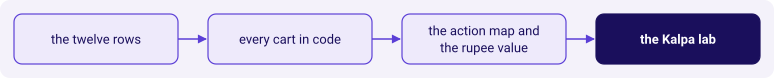

In [2]:
kit.flow(["the twelve rows",
          "every cart in code",
          "the action map and the rupee value",
          "the Kalpa lab"],
         lit=3, show=True)

## Your turn: how often is the Rs 199 phone charger in a basket?

Write two or three lines that compute the charger's share of the consumer baskets, then
the share of baskets that hold the charger and a screen protector, then the confidence
from screen protector to charger. The cell is empty so no saved output names the number
before the room counts it.

**What a correct answer gives you.** The share of consumer baskets that hold the charger
sits very high. The confidence from screen protector to charger is close to that share,
and the lift of the pair sits near one, because the charger is in almost every basket.

## The strongest pair above a 5 percent support floor

For every two-item combination, record its support and its lift. Keep the pairs with
support of at least 5 percent and rank by lift.

In [3]:
baskets = consumer_items.groupby("order_id")["product_name"].apply(set)
n = len(baskets)
marg = consumer_items.groupby("product_name").order_id.nunique() / n
pair_counts = Counter()
for s in baskets:
    for a, b in combinations(sorted(s), 2):
        pair_counts[(a, b)] += 1
rows = []
for (a, b), count in pair_counts.items():
    sup = count / n
    lift = sup / (marg[a] * marg[b])
    rows.append((a, b, count, sup, lift))
pairs = pd.DataFrame(rows, columns=["a", "b", "count", "support", "lift"])
promote = pairs[pairs.support >= 0.05].sort_values("lift", ascending=False)
print(promote.head(5).to_string(index=False))
kit.check("there is at least one pair above the 5 percent floor", len(promote) >= 1)
kit.check("the top pair's lift is at least 2.5", promote.lift.iloc[0] >= 2.5)

                    a                   b  count  support     lift
        earphone case  wireless earphones     30    0.060 3.076923
          notebook A5          phone grip     25    0.050 1.635269
        LED desk lamp   phone charger 20W     70    0.140 1.055807
    phone charger 20W power bank 10000mAh     81    0.162 1.024668
earphone jack adapter   phone charger 20W     67    0.134 1.023682


## The thin surprise: the pair with support between 0.2 and 0.4 percent

The 5 percent floor keeps a sturdy promote list but hides smaller pairs the merchandising
team may still want to know about. Keep pairs whose support sits between 0.2 and 0.4
percent and look at the lift.

In [4]:
thin = pairs[(pairs.support >= 0.002) & (pairs.support <= 0.004)].sort_values("lift", ascending=False)
print(thin.head(5).to_string(index=False))
kit.check("the thin candidate has lift above 3", len(thin) > 0 and thin.lift.iloc[0] >= 3.0)

          a              b  count  support     lift
USB-C cable    car charger      2    0.004 4.000000
USB-C cable        pen set      2    0.004 1.234568
USB-C cable extension cord      2    0.004 1.123596
USB-C cable     phone grip      2    0.004 1.020408
USB-C cable  earphone case      1    0.002 0.769231


## A picture of the Kalpa map

Plot every Kalpa pair on lift against support with the 5 percent floor marked. The strong
pair, the thin surprise and the charger-partner all sit visibly.

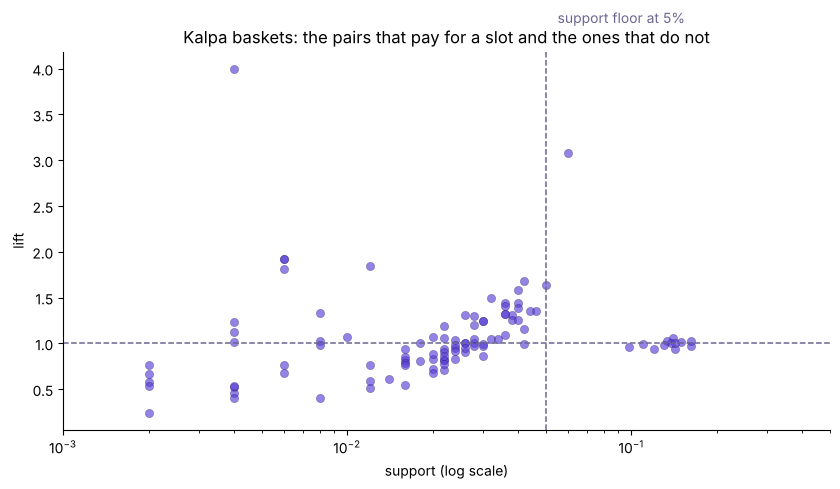

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(pairs.support, pairs.lift, s=35, color="#5B3FD6", alpha=0.65,
           edgecolor="#1A0F5C", linewidth=0.3)
ax.axhline(1.0, color="#6B6690", lw=1.1, ls="--")
ax.axvline(0.05, color="#6B6690", lw=1.1, ls="--")
ax.text(0.055, 4.5, "support floor at 5%", color="#6B6690", fontsize=10)
ax.set_xscale("log")
ax.set_xlim(0.001, 0.5)
ax.set_xlabel("support (log scale)")
ax.set_ylabel("lift")
ax.set_title("Kalpa baskets: the pairs that pay for a slot and the ones that do not")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()
kit.check("the plot ran", True)

## The map at the end of the lab

The method survives the change of company. The next lab, Thursday's Zomato Gold lab, asks
a different question: who is leaving the Retail-Plus tier, and at which step of the app
funnel.

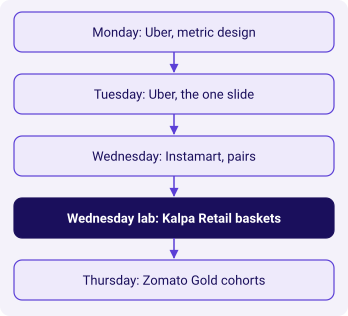

In [6]:
kit.vflow(["Monday: Uber, metric design",
           "Tuesday: Uber, the one slide",
           "Wednesday: Instamart, pairs",
           "Wednesday lab: Kalpa Retail baskets",
           "Thursday: Zomato Gold cohorts"],
          lit=3, show=True)

In [7]:
kit.check_summary()